# Benchmark

# Set up

In [1]:
cd ..

k:\Gen AI\project\retail_rag


# 1.) Collection stats

In [2]:
from app.services.milvus_service import get_client
from pprint import pprint

c = get_client("retail_db")

# print(c.get_collection_stats("wongnai_review_coll"))
# print(c.describe_collection("wongnai_review_coll"))

pprint(c.get_collection_stats("wongnai_review_coll"), sort_dicts=False, width=100)
print()
pprint(c.describe_collection("wongnai_review_coll"), sort_dicts=False, width=100)

{'row_count': 40000}

{'collection_name': 'wongnai_review_coll',
 'auto_id': False,
 'num_shards': 1,
 'description': '',
 'fields': [{'field_id': 100,
             'name': 'id',
             'description': '',
             'type': <DataType.INT64: 5>,
             'params': {},
             'is_primary': True},
            {'field_id': 101,
             'name': 'vector',
             'description': '',
             'type': <DataType.FLOAT_VECTOR: 101>,
             'params': {'dim': 1536}}],
 'functions': [],
 'aliases': [],
 'collection_id': 468258953813079865,
 'consistency_level': 2,
 'properties': {},
 'num_partitions': 1,
 'enable_dynamic_field': True,
 'enable_namespace': False,
 'created_timestamp': 468261186505015306,
 'update_timestamp': 468261186505015306}


# 2.) Disk space

Milvus keeps almost nothing on its own volume — entity data and indexes live in
MinIO under `a-bucket/files/`:

| Kind | Holds |
|---|---|
| `insert_log` | one binlog per field — vectors, text, scalars |
| `index_files` | the built vector index, one tree per index build |
| `stats_log` / `delta_log` | per-segment statistics and deletions |

`du` runs inside a throwaway `alpine` container: the MinIO image ships no `du`,
and Docker Desktop keeps the volumes off the host filesystem.

In [3]:
import re
import subprocess

# The docker-compose stack backing Milvus. Run `docker volume ls` if these differ.
MINIO_VOLUME = "data_server_minio_data"
MILVUS_VOLUME = "data_server_milvus_data"
BUCKET = "a-bucket"


def alpine(script: str, timeout: float = 300) -> str:
    """Run a shell snippet against the Milvus volumes in a throwaway container."""
    result = subprocess.run(
        ["docker", "run", "--rm",
         "-v", f"{MINIO_VOLUME}:/minio", "-v", f"{MILVUS_VOLUME}:/milvus",
         "alpine", "sh", "-c", script],
        capture_output=True, text=True, timeout=timeout,
    )
    return result.stdout


def du(*paths: str) -> dict[str, int]:
    """Return {path: bytes} for each path; missing paths are simply absent."""
    output = alpine(" ".join(f'du -sb "{p}" 2>/dev/null;' for p in paths))

    sizes = {}
    for line in output.splitlines():
        size, _, path = line.partition("\t")
        if path:
            sizes[path.strip()] = int(size)
    return sizes


def human(n: float | None) -> str:
    """Bytes as a short human-readable string."""
    if n is None:
        return "-"
    for unit in ["B", "KB", "MB", "GB", "TB"]:
        if abs(n) < 1024:
            return f"{n:,.0f} B" if unit == "B" else f"{n:,.1f} {unit}"
        n /= 1024
    return f"{n:,.1f} PB"


# Sanity check: docker reachable and the volume mounted where we expect.
print(alpine(f"ls /minio/{BUCKET}/files")
      or "!! bucket not found -- check MINIO_VOLUME / BUCKET")

index_files
insert_log
stats_log



In [4]:
import pandas as pd

# Keyed by collection id, so these can be sized directly. index_files is keyed
# by index build id instead and needs the separate lookup below.
SEGMENT_KINDS = ["insert_log", "delta_log", "stats_log"]


def segment_ids(collection_id: str) -> set[str]:
    """Segment ids owned by a collection, read from its insert_log tree."""
    listing = alpine(
        f"ls /minio/{BUCKET}/files/insert_log/{collection_id} 2>/dev/null",
        timeout=120,
    )
    return {s.strip() for s in listing.split() if s.strip()}


def index_sizes_by_segment() -> dict[str, int]:
    """Map segment id -> index bytes, summed over every build id and version.

    index_files is laid out as <build_id>/<version>/<segment_id>/, so a
    collection's index cost is the sum over the segments it owns. Re-indexing
    leaves older build ids behind; they are counted because they occupy real
    disk until Milvus GC removes them.
    """
    listing = alpine(f"du -sb /minio/{BUCKET}/files/index_files/*/*/*/ 2>/dev/null")

    per_segment: dict[str, int] = {}
    for line in listing.splitlines():
        size, _, path = line.partition("\t")
        match = re.search(r"/index_files/[^/]+/[^/]+/([^/]+)/?$", path.strip())
        if match:
            per_segment[match.group(1)] = per_segment.get(match.group(1), 0) + int(size)

    return per_segment


def storage_report(database: str = "retail_db") -> pd.DataFrame:
    """One row per collection with its on-disk footprint, largest first."""
    client = get_client(database)
    index_by_segment = index_sizes_by_segment()

    collections = []
    for name in client.list_collections():
        desc = client.describe_collection(name)
        dim = next((f["params"].get("dim") for f in desc["fields"]
                    if f.get("params", {}).get("dim")), None)
        collections.append({
            "collection": name,
            "collection_id": str(desc["collection_id"]),
            "rows": client.get_collection_stats(name).get("row_count", 0),
            "dim": dim,
        })

    # A single container run for every (collection, kind) pair, not one each.
    sizes = du(*[f"/minio/{BUCKET}/files/{kind}/{c['collection_id']}"
                 for c in collections for kind in SEGMENT_KINDS])

    rows = []
    for c in collections:
        per_kind = {
            kind: sizes.get(f"/minio/{BUCKET}/files/{kind}/{c['collection_id']}", 0)
            for kind in SEGMENT_KINDS
        }
        index_bytes = sum(index_by_segment.get(s, 0) for s in segment_ids(c["collection_id"]))
        total = sum(per_kind.values()) + index_bytes

        rows.append({
            "collection": c["collection"],
            "rows": c["rows"],
            "dim": c["dim"],
            "insert_log": per_kind["insert_log"],
            "index_files": index_bytes,
            "other_logs": per_kind["delta_log"] + per_kind["stats_log"],
            "total_bytes": total,
            "bytes_per_row": total / c["rows"] if c["rows"] else None,
            # What the vectors alone would cost as raw float32, for comparison.
            "vector_payload": c["rows"] * c["dim"] * 4 if c["dim"] else None,
        })

    return pd.DataFrame(rows).sort_values("total_bytes", ascending=False)


storage = storage_report("retail_db")

BYTE_COLUMNS = ["insert_log", "index_files", "other_logs",
                "total_bytes", "bytes_per_row", "vector_payload"]

# Formatted into a display copy so `storage` keeps its numeric dtypes.
pretty = storage.assign(**{c: storage[c].map(human) for c in BYTE_COLUMNS})
display(pretty.set_index("collection"))

,rows,dim,insert_log,index_files,other_logs,total_bytes,bytes_per_row,vector_payload
collection,,,,,,,,
wongnai_review_coll,40000,1536,627.7 MB,481.3 MB,788.5 KB,1.1 GB,28.4 KB,234.4 MB


In [5]:
volumes = du("/minio", "/milvus")

accounted = storage["total_bytes"].sum()
minio_total = volumes.get("/minio", 0)
milvus_total = volumes.get("/milvus", 0)

for row in storage.itertuples():
    print(f"{row.collection}")
    print(f"  rows           {row.rows:,} x {row.dim}d")
    print(f"  vector payload {human(row.vector_payload)}  (float32, no overhead)")
    print(f"  actual on disk {human(row.total_bytes)}"
          f"  ({row.total_bytes / row.vector_payload:.1f}x)")
    print(f"  per row        {human(row.bytes_per_row)}")
    print()

print(f"MinIO volume      {human(minio_total)}")
print(f"  accounted for   {human(accounted)}  ({len(storage)} collections)")
print(f"  unaccounted     {human(minio_total - accounted)}  (other dbs / orphaned, pending GC)")
print(f"Milvus volume     {human(milvus_total)}  (WAL + local metadata)")
print("-" * 42)
print(f"Total on disk     {human(minio_total + milvus_total)}")

wongnai_review_coll
  rows           40,000 x 1536d
  vector payload 234.4 MB  (float32, no overhead)
  actual on disk 1.1 GB  (4.7x)
  per row        28.4 KB

MinIO volume      1.1 GB
  accounted for   1.1 GB  (1 collections)
  unaccounted     879.7 KB  (other dbs / orphaned, pending GC)
Milvus volume     274.1 MB  (WAL + local metadata)
------------------------------------------
Total on disk     1.4 GB


# 3.) Retrieval latency

In [ ]:
import json
from pathlib import Path

# Thai evaluation queries, loaded from data/eval/thai_queries.jsonl so the set
# is version-controlled and shared rather than pasted into a notebook cell.
# See data/eval/README.md for the schema and why the ordering matters.
QUERY_FILE = Path("data/eval/thai_queries.jsonl")

query_rows = [json.loads(line) for line
              in QUERY_FILE.read_text(encoding="utf-8").splitlines() if line.strip()]

# Order is significant: section 4 sweeps N = 10, 20, ... 100 by taking the first
# N, and the file is ordered so any prefix stays a balanced mix of intents.
query_rows.sort(key=lambda r: r["id"])

queries = [r["query"] for r in query_rows]
INTENTS = [r["intent"] for r in query_rows]

print(f"{len(queries)} queries from {QUERY_FILE}")
print(f"  {sum(r['sentiment'] == 'negative' for r in query_rows)} negative, "
      f"{sum(r['in_latency_set'] for r in query_rows)} in the latency set")

In [ ]:
import time
from app.services import milvus_service

# Pinned to the original 10: `queries` grew to 100 for the section 4 sweep, and
# the latency figures recorded in docs/phase_1/benchmark.md are a 10-query run.
LATENCY_QUERIES = queries[:10]

milvus_service.search("warm up")          # exclude cold-start

for q in LATENCY_QUERIES:                    # Thai queries
    t = time.perf_counter()
    milvus_service.search(q)
    print(f"{time.perf_counter() - t:.3f}s")

# 4.) Retrieval quality — RAGAS

Two LLM-judged metrics, on opposite sides of the pipeline:

| Metric | Judges | Fails when |
|---|---|---|
| **Context precision** | Retriever | top-5 is padded with reviews that merely share vocabulary |
| **Faithfulness** | Generator | the answer asserts what the reviews never said |

The split is what makes the pair diagnostic: low precision + high faithfulness
blames retrieval, the reverse blames the LLM, both low blames the embedding model.

Neither needs a ground-truth answer, which is the point — the labelled Thai eval
set is Phase 6 work, so `LLMContextPrecisionWithoutReference` judges each chunk
against the *generated* answer instead. The catch: that makes the two metrics
non-independent (a bad chunk the LLM answered from still looks "relevant"), so
this does **not** retire the Phase 6 set.

### The sweep

100 hand-written Thai queries from [`data/eval/thai_queries.jsonl`](../data/eval/thai_queries.jsonl)
(loaded by the first cell below, so this section runs standalone), evaluated
at **N = 10, 20, 30 … 100**, so the
scores can be read as a curve rather than a single number. The question it
answers: *how many queries does a stable estimate actually need?* If the lines
flatten by N=40, evaluating 100 every time is waste.

Each point re-judges the first N records from scratch — ragas has no partial
accumulation, and re-judging is what makes N=10 and N=100 comparable — so total
cost grows roughly quadratically across the sweep.

### If the kernel restarts

Answers are written to `data/eval/rag_responses.jsonl` the moment generation
finishes, before any judging. To resume a sweep without paying to regenerate,
run the config cell below, then this instead of the generation cell:

```python
records = [
    {k: r[k] for k in ("user_input", "response", "retrieved_contexts")}
    for r in (json.loads(line) for line
              in Path("data/eval/rag_responses.jsonl").read_text(encoding="utf-8").splitlines()
              if line.strip())
]
sweep_frames = {}
```

### The budget guard

Hard cap of **$1.50** (~50.10 THB). Cost is projected *before* each batch; if the
projection would cross the cap the batch is skipped and everything already paid
for is kept. The cap is therefore never exceeded, only approached.

Judge is **gpt-5-nano** ($0.05/1M in, $0.40/1M out) — 50× cheaper on input than
gpt-4o, and in RAG input dominates because five retrieved reviews dwarf the
question. That is what makes N=100 affordable.

> **Two caveats that come with that choice.**
>
> **The judge is the same model as the generator**, because `gpt-5-nano` is the
> only model this API key can reach — every `gpt-4o` / `gpt-4.1` candidate
> returns `403 model_not_found`. A model grading its own answers is a weaker
> check than an independent judge. Revisit if the project gains model access.
>
> **The judge runs at `temperature=1`**, not 0. ragas hardcodes `0.01` and
> writes it onto the client before every call; `gpt-5-*` reject anything but the
> default with a 400, and ragas catches those per job — so the run completes and
> returns **NaN for every score**. `PinnedTempChatOpenAI` in the sweep cell drops
> the parameter from the request payload so the API never sees it. The cost is
> that verdicts vary slightly between runs.

> Prices verified against `developers.openai.com/api/docs/pricing` on 2026-08-13,
> and hardcoded in `PRICING` below. Re-check before trusting a cost estimate.

Requires `pip install "ragas==0.4.3" langchain-openai`. Pin it — the judge
prompts ship with the library, so an unpinned upgrade moves the scores on its own.

In [2]:
# Preflight. Two things worth checking before spending money:
#
# 1. ragas is mid-migration -- the metric classes moved to
#    ragas.metrics.collections, and the flat ragas.metrics imports used below
#    are deprecated in 0.4 / removed in 1.0. Field names changed in 0.2 too.
# 2. mlflow is optional. Its absence only disables the logging cells at the end;
#    the evaluation itself does not touch it.
import importlib.metadata as md

REQUIRED = {
    "ragas": 'pip install "ragas==0.4.3"',
    "langchain-openai": "pip install langchain-openai",
    "langchain-core": "(installed with langchain-openai)",
}
OPTIONAL = {
    "mlflow": "pip install mlflow   # only for the logging cells at the end",
    "boto3": "pip install boto3     # only for MLflow *artifacts* -- see the MLflow cell",
}

for group, packages in [("required", REQUIRED), ("optional", OPTIONAL)]:
    print(f"-- {group} --")
    for package, hint in packages.items():
        try:
            print(f"  {package:18} {md.version(package)}")
        except md.PackageNotFoundError:
            print(f"  {package:18} NOT INSTALLED  ->  {hint}")


-- required --
  ragas              0.4.3
  langchain-openai   1.5.0
  langchain-core     1.5.4
-- optional --
  mlflow             3.13.0
  boto3              1.43.73


In [3]:
import json
import time
from pathlib import Path

import tiktoken

from app.config import settings
from app.services.rag_service import answer_query

# ----------------------------------------------------------------- queries --
# Loaded here as well as in section 3 so section 4 runs standalone -- on a
# fresh kernel you can jump straight to this section without executing the
# latency run above. See data/eval/README.md for the schema; the ordering is
# significant because the sweep below evaluates the first N.
QUERY_FILE = Path("data/eval/thai_queries.jsonl")

query_rows = sorted(
    (json.loads(line) for line
     in QUERY_FILE.read_text(encoding="utf-8").splitlines() if line.strip()),
    key=lambda r: r["id"],
)
queries = [r["query"] for r in query_rows]
INTENTS = [r["intent"] for r in query_rows]

print(f"queries     {len(queries)} from {QUERY_FILE}")

# ---------------------------------------------------------------- budget ----
BUDGET_USD = 1.50           # hard cap, ~50.10 THB
STEP = 10                   # sweep at N = 10, 20, 30, ...

# gpt-5-nano is the only model this API key can reach -- every gpt-4o / gpt-4.1
# candidate returns 403 model_not_found, so the judge and the generator are
# necessarily the same model here. Worth stating plainly: a model grading its
# own output is a weaker check than an independent judge would be. Revisit if
# the project gains access to another model.
#
# gpt-5-* accept only the default temperature=1, while ragas hardcodes 0.01 and
# writes it onto the client before every call. See PinnedTempChatOpenAI in the
# sweep cell for how that is neutralised.
JUDGE_MODEL = "gpt-5-nano"

# USD per 1M tokens. Verified against developers.openai.com/api/docs/pricing
# on 2026-08-13 -- re-check before trusting a cost estimate, these move.
PRICING = {
    "gpt-5-nano":            {"in": 0.05, "cached_in": 0.005, "out": 0.40},
    "gpt-5-mini":            {"in": 0.25, "cached_in": 0.025, "out": 2.00},
    "gpt-4o":                {"in": 2.50, "cached_in": 1.25,  "out": 10.00},
    "gpt-4o-mini":           {"in": 0.15, "cached_in": 0.075, "out": 0.60},
    "text-embedding-3-small": {"in": 0.02, "cached_in": 0.0,  "out": 0.0},
}


def cost_usd(model: str, tokens_in: int = 0, tokens_out: int = 0,
             cached_in: int = 0) -> float:
    """USD for a call. Input dominates in RAG -- chunks dwarf the question."""
    rate = PRICING[model]
    return (tokens_in / 1e6 * rate["in"]
            + cached_in / 1e6 * rate["cached_in"]
            + tokens_out / 1e6 * rate["out"])


_encoding = tiktoken.get_encoding("cl100k_base")

def ntokens(text: str) -> int:
    """Approximate token count. cl100k is not gpt-5's tokenizer, but it is the
    right order of magnitude and Thai text tokenizes heavily either way."""
    return len(_encoding.encode(text))


class Budget:
    """Running spend against a hard cap.

    `can_afford` is asked *before* each batch so the cap is never exceeded --
    a batch that would cross it is skipped, and everything already paid for
    is kept.
    """

    def __init__(self, limit_usd: float):
        self.limit = limit_usd
        self.spent = 0.0
        self.ledger = []

    def charge(self, label: str, usd: float) -> float:
        self.spent += usd
        self.ledger.append({"label": label, "usd": usd, "cumulative": self.spent})
        return self.spent

    def can_afford(self, usd: float) -> bool:
        return self.spent + usd <= self.limit

    @property
    def remaining(self) -> float:
        return max(0.0, self.limit - self.spent)

    def __repr__(self) -> str:
        pct = 100 * self.spent / self.limit if self.limit else 0
        return (f"${self.spent:.4f} / ${self.limit:.2f} ({pct:.1f}%)  "
                f"remaining ${self.remaining:.4f}")


budget = Budget(BUDGET_USD)
print(f"budget      {budget}")
print(f"judge       {JUDGE_MODEL}  "
      f"(in ${PRICING[JUDGE_MODEL]['in']}/1M, out ${PRICING[JUDGE_MODEL]['out']}/1M)")
print(f"generator   {settings.llm_model}  via {settings.llm_provider}")
print(f"sweep       N = {list(range(STEP, len(queries) + 1, STEP))}")

DASHSCOPE_API_KEY not set. Qwen service will fail on generate_answer().


queries     100 from data\eval\thai_queries.jsonl
budget      $0.0000 / $1.50 (0.0%)  remaining $1.5000
judge       gpt-5-nano  (in $0.05/1M, out $0.4/1M)
generator   gpt-5-nano  via openai
sweep       N = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]


In [4]:
import pandas as pd

# Generate answers for all 100 queries once, up front. The sweep then slices
# this list -- N=20 reuses the first 20 records rather than re-generating them,
# so generation is paid for once instead of once per sweep point.
#
# Generation is charged per query *as it goes*, and the loop stops the moment
# the next answer would breach the cap. The guard has to live here too: with
# long Thai contexts, generation alone can exhaust the budget before the sweep
# ever starts, and a warning printed after the money is spent is not a guard.
#
# GENERATION_SHARE reserves headroom for the judge -- spending the whole budget
# on answers would leave nothing to evaluate them with.
GENERATION_SHARE = 0.60

# ragas field names (renamed in 0.2): user_input / response / retrieved_contexts
records = []
generation_cost = 0.0
embedding_cost = 0.0        # query embeddings, one per question
generation_cap = budget.limit * GENERATION_SHARE
started = time.perf_counter()

for i, q in enumerate(queries, 1):
    result = answer_query(q, top_k=5)
    contexts = [doc["text"] for doc in result["sources"]]

    # The generator sees system prompt + joined chunks + question.
    tokens_in = ntokens(" ".join(contexts)) + ntokens(q) + 60
    tokens_out = ntokens(result["answer"])
    this_call = cost_usd(settings.llm_model, tokens_in, tokens_out)

    # Every query is also embedded once before the vector search. Tiny next to
    # generation, but it is real spend and the budget should not pretend
    # otherwise -- at $0.02/1M it is the rounding error that proves the ledger
    # is complete rather than approximate.
    this_embed = cost_usd(settings.embedding_model, tokens_in=ntokens(q))
    embedding_cost += this_embed

    generation_cost += this_call
    records.append({
        "user_input": q,
        "response": result["answer"],
        "retrieved_contexts": contexts,
    })

    if i % 10 == 0 or i == len(queries):
        print(f"  {i:3}/{len(queries)}  ${generation_cost:.4f}")

    # Stop before the *next* answer if it would eat the generation allowance.
    if (generation_cost + embedding_cost + this_call + this_embed
            > generation_cap and i < len(queries)):
        print(f"\n!! generation stopped at {i}/{len(queries)} queries: "
              f"${generation_cost:.4f} of the ${generation_cap:.2f} allowance "
              f"({GENERATION_SHARE:.0%} of the ${budget.limit:.2f} cap)")
        print(f"   the sweep will run over the {len(records)} answers generated")
        break

budget.charge("generation", generation_cost)
budget.charge("query embeddings", embedding_cost)
sweep_frames = {}          # N -> per-query frame, filled by the sweep below

# ------------------------------------------------------- persist immediately --
# Written the moment generation finishes, before any judging. These answers are
# the expensive half of the run and previously lived only in memory: a kernel
# restart (or an import error in the sweep cell below) discarded everything that
# had just been paid for. Saving here also makes the sweep re-runnable without
# regenerating -- see the reload snippet in the markdown cell above.
#
# Written to a temp file and then replaced, so an interrupt mid-write cannot
# leave a truncated file where a complete one used to be.
RESPONSE_FILE = Path("data/eval/rag_responses.jsonl")
RESPONSE_FILE.parent.mkdir(parents=True, exist_ok=True)

_tmp = RESPONSE_FILE.with_suffix(".jsonl.tmp")
with _tmp.open("w", encoding="utf-8") as fh:
    for position, record in enumerate(records):
        fh.write(json.dumps({
            "id": query_rows[position]["id"],
            "intent": query_rows[position]["intent"],
            "user_input": record["user_input"],
            "response": record["response"],
            "retrieved_contexts": record["retrieved_contexts"],
            "generator_model": settings.llm_model,
            "top_k": settings.top_k,
            "collection": f"{settings.milvus_database}/{settings.milvus_collection}",
        }, ensure_ascii=False) + "\n")
_tmp.replace(RESPONSE_FILE)

print(f"saved       {len(records)} responses -> {RESPONSE_FILE} "
      f"({RESPONSE_FILE.stat().st_size / 1024:.0f} KB)")

print(f"\n{len(records)} answers in {time.perf_counter() - started:.1f}s")
print(f"generation   ${generation_cost:.4f}  ({settings.llm_model})")
print(f"embeddings   ${embedding_cost:.4f}  ({settings.embedding_model})")
print(f"budget       {budget}")

if len(records) < STEP:
    print(f"\n!! fewer than {STEP} answers -- the sweep needs at least one full "
          f"step. Use a cheaper settings.llm_model or raise BUDGET_USD.")

   10/100  $0.0016
   20/100  $0.0036
   30/100  $0.0053
   40/100  $0.0071
   50/100  $0.0088
   60/100  $0.0106
   70/100  $0.0122
   80/100  $0.0144
   90/100  $0.0162
  100/100  $0.0185
saved       100 responses -> data\eval\rag_responses.jsonl (678 KB)

100 answers in 2467.8s
generation   $0.0185  (gpt-5-nano)
embeddings   $0.0000  (text-embedding-3-small)
budget       $0.0185 / $1.50 (1.2%)  remaining $1.4815


In [6]:
1

1

In [7]:
from langchain_openai import ChatOpenAI
from ragas import EvaluationDataset, evaluate
from ragas.llms import LangchainLLMWrapper
from ragas.metrics import Faithfulness, LLMContextPrecisionWithoutReference

class PinnedTempChatOpenAI(ChatOpenAI):
    """A ChatOpenAI that never sends `temperature` to the API.

    ragas hardcodes temperature=0.01 and assigns it onto the client before every
    call (LangchainLLMWrapper.generate_text), so whatever ChatOpenAI was built
    with is discarded. gpt-5-* accept only the default temperature=1 and reject
    anything else with a 400 -- and ragas catches those per job, so the run
    completes normally and every score comes back NaN. That failure is silent
    and costs a full sweep to discover.

    Overriding the attribute does not help (pydantic writes through it), so the
    parameter is dropped from the request payload instead: ragas can set the
    attribute all it likes, the API never sees it.
    """

    def _get_request_payload(self, *args, **kwargs):
        payload = super()._get_request_payload(*args, **kwargs)
        payload.pop("temperature", None)
        return payload


# Judge passed explicitly: these scores grade the judge as much as the pipeline,
# so an unrecorded judge makes them unreadable later. Note the judge runs at the
# model default (temperature=1) rather than 0 -- gpt-5-* allow nothing else, so
# verdicts will vary slightly between runs. Record the run id when comparing.
judge = LangchainLLMWrapper(
    PinnedTempChatOpenAI(model=JUDGE_MODEL, api_key=settings.openai_api_key)
)

# ragas re-sends the context once per extracted claim (faithfulness) and once
# per retrieved chunk (context precision). 6x is a deliberate over-estimate:
# the guard must never let an under-estimate breach the cap, so it errs toward
# stopping early rather than overspending.
JUDGE_PASSES = 6
JUDGE_OUT_TOKENS = 250          # per query, both metrics, short verdicts

INPUT_COLUMNS = {"user_input", "response", "retrieved_contexts", "reference"}


def estimate_judge_cost(batch: list[dict]) -> float:
    """Projected judge spend for a batch, computed *before* running it."""
    tokens_in = sum(
        ntokens(" ".join(r["retrieved_contexts"]))
        + ntokens(r["response"]) + ntokens(r["user_input"])
        for r in batch
    )
    return cost_usd(JUDGE_MODEL,
                    tokens_in=tokens_in * JUDGE_PASSES,
                    tokens_out=JUDGE_OUT_TOKENS * len(batch))


def score_columns_of(frame) -> list[str]:
    """Score columns are named after the metric classes and have been renamed
    across ragas releases -- detect them instead of hardcoding."""
    return [c for c in frame.columns
            if c not in INPUT_COLUMNS and pd.api.types.is_numeric_dtype(frame[c])]


# ------------------------------------------------------------- the sweep ----
# Each point re-judges the first N records from scratch. ragas has no partial
# accumulation, and re-judging is what makes N=10 and N=100 directly comparable.
# Total cost is therefore ~quadratic in the number of points, which is exactly
# why the guard runs before every batch rather than after.
sweep_points = list(range(STEP, len(records) + 1, STEP))
sweep_results = []
stopped_at = None

print(f"sweep N = {sweep_points}")
print(f"start {budget}\n")

for n in sweep_points:
    projected = estimate_judge_cost(records[:n])

    if not budget.can_afford(projected):
        stopped_at = n
        print(f"\n!! STOP before N={n}")
        print(f"   projected ${projected:.4f} would reach "
              f"${budget.spent + projected:.4f}, over the ${budget.limit:.2f} cap")
        print(f"   completed N = {[r['n'] for r in sweep_results]}")
        break

    print(f"N={n:3}  projected ${projected:.4f}  running ${budget.spent:.4f}")
    started = time.perf_counter()

    result = evaluate(
        dataset=EvaluationDataset.from_list(records[:n]),
        metrics=[LLMContextPrecisionWithoutReference(), Faithfulness()],
        llm=judge,
    )
    elapsed = time.perf_counter() - started

    # Charge the projection: ragas does not expose real token usage, so the
    # ledger tracks the same conservative figure the guard decided on.
    budget.charge(f"judge N={n}", projected)

    frame = result.to_pandas()
    sweep_frames[n] = frame

    row = {"n": n, "seconds": elapsed, "cost_usd": projected,
           "cumulative_usd": budget.spent}
    for c in score_columns_of(frame):
        row[c] = frame[c].mean()
        row[f"{c}__std"] = frame[c].std()
    sweep_results.append(row)

    scores_text = "  ".join(f"{c}={row[c]:.3f}" for c in score_columns_of(frame))
    print(f"       {scores_text}   {elapsed:.1f}s\n")

sweep = pd.DataFrame(sweep_results)
print(f"final  {budget}")
if stopped_at:
    print(f"stopped before N={stopped_at} -- {len(sweep)} of "
          f"{len(sweep_points)} points completed")

C:\Users\Kao\AppData\Local\Temp\ipykernel_20940\10386086.py:4: DeprecationWarning: Importing Faithfulness from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import Faithfulness
  from ragas.metrics import Faithfulness, LLMContextPrecisionWithoutReference
C:\Users\Kao\AppData\Local\Temp\ipykernel_20940\10386086.py:4: DeprecationWarning: Importing LLMContextPrecisionWithoutReference from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import LLMContextPrecisionWithoutReference
  from ragas.metrics import Faithfulness, LLMContextPrecisionWithoutReference
C:\Users\Kao\AppData\Local\Temp\ipykernel_20940\10386086.py:31: DeprecationWarning: LangchainLLMWrapper is deprecated and will be removed in a future version. Use llm_factory instead: from openai import OpenAI; from ragas.llms import llm_fact

sweep N = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
start $0.4157 / $1.50 (27.7%)  remaining $1.0843

N= 10  projected $0.0067  running $0.4157


Evaluating: 100%|██████████| 20/20 [01:26<00:00,  4.32s/it]


       llm_context_precision_without_reference=0.831  faithfulness=0.096   86.7s

N= 20  projected $0.0138  running $0.4223


Evaluating: 100%|██████████| 40/40 [02:29<00:00,  3.73s/it]


       llm_context_precision_without_reference=0.794  faithfulness=0.112   149.1s

N= 30  projected $0.0210  running $0.4361


... (12 outputs left out)

Evaluating: 100%|██████████| 180/180 [09:14<00:00,  3.08s/it]


       llm_context_precision_without_reference=0.808  faithfulness=0.089   554.1s

N=100  projected $0.0765  running $0.7364


Evaluating: 100%|██████████| 200/200 [09:46<00:00,  2.93s/it]

       llm_context_precision_without_reference=0.795  faithfulness=0.090   587.0s

final  $0.8129 / $1.50 (54.2%)  remaining $0.6871


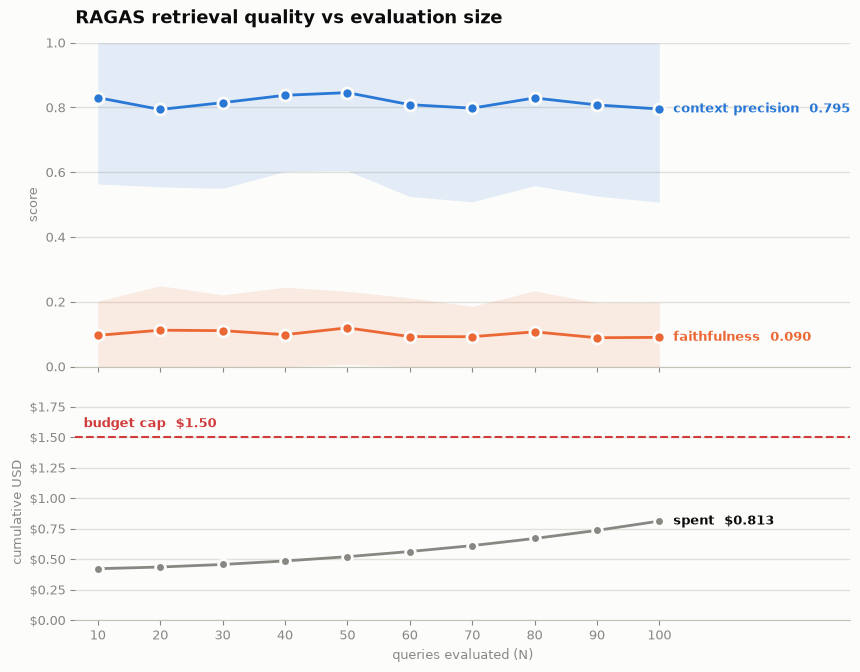

  n  llm_context_precision_without_reference  faithfulness  cost_usd  cumulative_usd  seconds
 10                                    0.831         0.096     0.007           0.422   86.744
 20                                    0.794         0.112     0.014           0.436  149.095
 30                                    0.815         0.111     0.021           0.457  197.415
 40                                    0.838         0.098     0.029           0.486  254.584
 50                                    0.846         0.120     0.035           0.521  297.243
 60                                    0.809         0.093     0.042           0.563  480.993
 70                                    0.798         0.092     0.049           0.612  506.826
 80                                    0.829         0.107     0.059           0.670  514.539
 90                                    0.808         0.089     0.066           0.736  554.091
100                                    0.795         0.090  

In [8]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Two panels sharing an x-axis rather than one chart with twin y-axes: scores
# are 0-1 and cost is USD, and a dual-axis plot lets the reader infer whatever
# relationship the rescaling implies. Separate panels keep the comparison honest.
#
# Palette: categorical slots 1-2, validated for CVD separation in both modes.
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
SURFACE, CRITICAL = "#fcfcfb", "#d03b3b"

if sweep.empty:
    raise SystemExit("no completed sweep points -- nothing to plot. "
                     "Raise BUDGET_USD or use a cheaper generator.")

score_cols = [c for c in sweep.columns
              if c not in {"n", "seconds", "cost_usd", "cumulative_usd"}
              and not c.endswith("__std")]

# Friendlier names; ragas column names are long and version-dependent.
LABELS = {c: ("context precision" if "precision" in c or "utilization" in c
              else "faithfulness" if "faith" in c else c)
          for c in score_cols}

fig, (ax_score, ax_cost) = plt.subplots(
    2, 1, figsize=(10, 7.5), sharex=True, height_ratios=[3, 2],
    gridspec_kw={"hspace": 0.14},
)
fig.patch.set_facecolor(SURFACE)

# -- top: scores vs N, with +/-1 std as a band -------------------------------
for colour, col in zip((BLUE, ORANGE), score_cols):
    ax_score.plot(sweep["n"], sweep[col], color=colour, linewidth=2,
                  marker="o", markersize=8, markeredgecolor=SURFACE,
                  markeredgewidth=2, label=LABELS[col], zorder=3)

    std_col = f"{col}__std"
    if std_col in sweep:
        ax_score.fill_between(sweep["n"],
                              (sweep[col] - sweep[std_col]).clip(lower=0),
                              (sweep[col] + sweep[std_col]).clip(upper=1),
                              color=colour, alpha=0.12, linewidth=0, zorder=1)

    # Direct-label the last point so identity never rests on colour alone.
    last = sweep.iloc[-1]
    ax_score.annotate(f"{LABELS[col]}  {last[col]:.3f}",
                      (last["n"], last[col]), xytext=(10, 0),
                      textcoords="offset points", color=colour,
                      fontsize=9.5, va="center", fontweight="bold")

# Zoom to the data with headroom rather than pinning 0-1: the whole question is
# whether the scores drift as N grows, and a 0-1 axis flattens that to a line.
# The +/-1 std band stays visible so the zoom cannot overstate a trend.
lo = min((sweep[c] - sweep.get(f"{c}__std", 0)).min() for c in score_cols)
hi = max((sweep[c] + sweep.get(f"{c}__std", 0)).max() for c in score_cols)
pad = max(0.05, (hi - lo) * 0.12)
ax_score.set_ylim(max(0, lo - pad), min(1.0, hi + pad))

# Room on the right for the direct labels, which otherwise run off the figure.
span = max(sweep["n"].iloc[-1] - sweep["n"].iloc[0], STEP)
ax_score.set_xlim(sweep["n"].iloc[0] - span * 0.04,
                  sweep["n"].iloc[-1] + span * 0.34)

ax_score.set_ylabel("score", color=MUTED, fontsize=9)
ax_score.set_title("RAGAS retrieval quality vs evaluation size",
                   color=INK, fontsize=13, fontweight="bold", loc="left", pad=14)

# -- bottom: cumulative spend against the cap --------------------------------
ax_cost.plot(sweep["n"], sweep["cumulative_usd"], color=MUTED, linewidth=2,
             marker="o", markersize=7, markeredgecolor=SURFACE,
             markeredgewidth=2, zorder=3)
ax_cost.axhline(BUDGET_USD, color=CRITICAL, linewidth=1.5, linestyle="--", zorder=2)
ax_cost.annotate(f"budget cap  ${BUDGET_USD:.2f}",
                 (ax_cost.get_xlim()[0], BUDGET_USD), xytext=(6, 5),
                 textcoords="offset points", color=CRITICAL, fontsize=9.5,
                 va="bottom", ha="left", fontweight="bold")

spent = sweep["cumulative_usd"].iloc[-1]
ax_cost.annotate(f"spent  ${spent:.3f}", (sweep["n"].iloc[-1], spent),
                 xytext=(10, 0), textcoords="offset points", color=INK,
                 fontsize=9.5, va="center", fontweight="bold")

ax_cost.set_ylim(0, max(BUDGET_USD, spent) * 1.18)
ax_cost.set_ylabel("cumulative USD", color=MUTED, fontsize=9)
ax_cost.set_xlabel("queries evaluated (N)", color=MUTED, fontsize=9)
ax_cost.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:.2f}"))

for ax in (ax_score, ax_cost):
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, labelsize=9)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")

ax_score.set_xticks(sweep["n"])

# Kept in `sweep_figure` so the MLflow cell can log it as an artifact --
# plt.show() detaches the figure from pyplot's registry.
sweep_figure = fig
plt.show()

# The table view, so nothing depends on reading colour off a chart.
print(sweep[["n", *score_cols, "cost_usd", "cumulative_usd", "seconds"]]
      .to_string(index=False, float_format="{:.3f}".format))

### Before trusting a low score

ragas decomposes claims and judges relevance with **English** prompts, over
**Thai** review text. A bad faithfulness score may therefore mean the judge
failed on Thai — a finding about ragas, not about the pipeline.

So read the worst queries by hand before drawing a conclusion. The cell below
prints the lowest-scoring ones in full.

In [ ]:
WORST_N = 3

# Inspect the largest completed sweep point -- it has the most queries and so
# the most chances to have caught a real failure.
if not sweep_frames:
    raise SystemExit("no completed sweep points -- nothing to inspect.")

largest = max(sweep_frames)
df = sweep_frames[largest]
cols = score_columns_of(df)
print(f"worst {WORST_N} of N={largest}\n")

# Rank by the weakest metric per row: a query that scored 0.9/0.2 is as much
# worth reading as one that scored 0.5/0.5. Ranked on a separate Series rather
# than an assigned column -- itertuples() mangles names starting with "_".
weakest = df[cols].min(axis=1)
worst = df.loc[weakest.nsmallest(WORST_N).index]

for position, row in enumerate(worst.itertuples(), 1):
    print("=" * 78)
    print(f"[{position}] " + "   ".join(
        f"{c}={getattr(row, c):.3f}" for c in cols))
    print(f"\nQ  {row.user_input}")
    print(f"\nA  {row.response}\n")

    for rank, context in enumerate(row.retrieved_contexts, 1):
        snippet = context.replace("\n", " ")[:200]
        print(f"  [{rank}] {snippet}")
    print()

# Judge it yourself: is the answer actually unsupported by those chunks, or did
# the judge simply not read Thai? Record the verdict in docs/phase_1/benchmark.md.

worst 3 of N=100

[1] llm_context_precision_without_reference=0.887   faithfulness=0.000

Q  ก๋วยเตี๋ยวเรืออร่อย น้ำซุปเข้มข้น

A  Sentiment: บวก 0.85 — น้ำซุปเข้มข้น
Issues: none
Precedent: ไม่พบใน corpus (ไม่มีประเด็นอ้างอิง)
Actions: รักษคุณภาพน้ำซุปเข้มข้นและรสชาติให้คงที่
Priority: low — เน้นรักษาคุณภาพรสชาติที่ลูกค้าชื่นชม

  [1] review: ก๋วยเตี๋ยวเรือท่าสยาม ร้านทีมีรสชาติเฉพาะตัว ด้วยก๋วยเตี๋ยวเรือเข้มข้น แล้วก็น้ำซุปที่แบบแซ่บเด็ดมากๆ ที่หลายๆ คนติดใจ ส่วนตัวชอบสั่งก๋วยเตี๋ยวเรือหมูตุ๋น เนื้อหมูนุ่มพอใช้ มีเหนียวบ้างปนๆกันค
  [2] review: ก๋วยเตี๋ยวเรือน้ำซุปจัดจ้านราคาย่อมเยาแริมาณไม่น้อยเหมือนราคา. ทานสองชาม หรือจะสั่งแบบพิเศษมาทานคู่กับแคปหมูก้ออกรสชาด. แถมยังมีลูกชิ้นปิ้ง. น้ำจิ้มข้มข้นรสเด็ดเรียกว่า ก๋วยเตี๋ยวเรือจากต้นตำห
  [3] review: ก๋วยเตี๋ยวเรือในตำนาน 5555 คือมีคนแนะนำว่าต้องไปกินให้ได้ แล้วจะลืมร้านเดิมที่เคยไปกินมาทั้งหมดเลย คิดใจใน "ขนาดนั้นเลยเหรออออ"  เราไปกันช่วงเช้า น่าจะ 9โมงกว่าๆ คือทานเป็นมื้อเช้าเลย รสชาตยัง
  [4] review: ก๋วยเตี๋ยวเรือรสเด็ด เผ็ดสะใจ พริ

In [10]:
# Spend ledger -- copy these into the run log in docs/phase_1/benchmark.md.
ledger = pd.DataFrame(budget.ledger)
print(ledger.to_string(index=False, float_format="{:.4f}".format))

print(f"\ntotal        ${budget.spent:.4f}  of ${budget.limit:.2f} cap")
print(f"             ~{budget.spent * 33.4:.2f} THB at 33.4 THB/USD")
print(f"remaining    ${budget.remaining:.4f}")
print(f"judge        {JUDGE_MODEL}   generator {settings.llm_model}")
print(f"sweep        N = {list(sweep['n'])}"
      + (f"  (stopped before {stopped_at})" if stopped_at else "  (complete)"))

# The estimate is deliberately conservative (JUDGE_PASSES=6), so real spend
# should come in *under* this. Reconcile against the OpenAI usage dashboard
# before quoting a cost figure as measured rather than projected.
print("\nNote: projected from token counts, not read back from OpenAI usage.")

           label    usd  cumulative
      generation 0.0185      0.0185
query embeddings 0.0000      0.0185
      judge N=10 0.0067      0.0252
      judge N=20 0.0138      0.0390
      judge N=30 0.0210      0.0600
      judge N=40 0.0287      0.0887
      judge N=50 0.0351      0.1237
      judge N=60 0.0422      0.1659
      judge N=70 0.0485      0.2144
      judge N=80 0.0585      0.2729
      judge N=90 0.0663      0.3392
     judge N=100 0.0765      0.4157
      judge N=10 0.0067      0.4223
      judge N=20 0.0138      0.4361
      judge N=30 0.0210      0.4572
      judge N=40 0.0287      0.4858
      judge N=50 0.0351      0.5209
      judge N=60 0.0422      0.5631
      judge N=70 0.0485      0.6116
      judge N=80 0.0585      0.6701
      judge N=90 0.0663      0.7364
     judge N=100 0.0765      0.8129

total        $0.8129  of $1.50 cap
             ~27.15 THB at 33.4 THB/USD
remaining    $0.6871
judge        gpt-5-nano   generator gpt-5-nano
sweep        N = [10, 20, 30

### Log the sweep to MLflow

Everything above lives in memory and dies with the kernel. This logs the sweep to
the tracking server at **`http://localhost:5000`** so the scores become a history
rather than one printout.

**Optional by design** — if `mlflow` is not installed or the server is
unreachable, the cell says so and moves on. Nothing above depends on it.

Shape: one **parent run** for the sweep, one **nested run per N**. Metrics are also
logged on the parent against `step=N`, so MLflow's own chart view plots
score-vs-N without any extra work, and the matplotlib figure is attached as an
artifact.

| Logged as | What |
|---|---|
| params | judge model, generator, ragas version, top_k, budget cap, query file, collection |
| metrics | context precision, faithfulness (+ std), cost, duration — per N |
| artifacts | sweep table (CSV), per-query scores at the largest N (question + answer + **full untruncated contexts**), the chart |
| tags | whether the budget guard fired, embedding model, dataset size |

> **Why the params matter more than usual.** These are LLM-judged scores, so the
> judge model and the ragas version are *part of the measurement*, not metadata.
> A metric history that doesn't record them isn't comparable across runs — which
> is the whole reason for logging in the first place.

> **Cost is a projection, not measured usage.** It is logged as
> `cost_usd_projected` so nobody later mistakes it for a figure read back from
> OpenAI billing.

MLflow also ships native RAGAS scorers (`mlflow.genai.scorers.ragas`), but those
re-judge through MLflow traces — which would pay for the judging a second time and
bypass the budget guard. The sweep already has the scores, so they are logged
directly.

Needs `pip install mlflow` and a server running:

```powershell
mlflow server --host 127.0.0.1 --port 5000
```

In [11]:
import importlib.metadata as md
import os
import sys

# MLflow 3 prints a "run finished" line containing an emoji when a run ends.
# On Windows the default console encoding is cp1252, which cannot encode it --
# that raises UnicodeEncodeError *after* the metrics are already logged, turning
# a successful run into a traceback. Force UTF-8 so the run closes cleanly.
if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8", errors="replace")
    sys.stderr.reconfigure(encoding="utf-8", errors="replace")

MLFLOW_TRACKING_URI = os.getenv("MLFLOW_TRACKING_URI", "http://localhost:5000")
MLFLOW_EXPERIMENT = "retail_rag/phase_1_ragas"

# Optional integration: a missing package or a down server must not invalidate
# an evaluation that has already been paid for. Both are treated as "skip and
# say so", never as an exception.
try:
    import mlflow
    mlflow_available = True
except ImportError:
    mlflow_available = False
    print("mlflow NOT INSTALLED  ->  pip install mlflow")
    print("Sweep results are still in `sweep` / `sweep_frames`; re-run this cell "
          "after installing to log them.")

if mlflow_available and sweep.empty:
    mlflow_available = False
    print("no completed sweep points -- nothing to log.")

if mlflow_available:
    mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)

    # Reachability is checked before opening a run, so a dead server does not
    # leave a half-written experiment behind.
    try:
        mlflow.set_experiment(MLFLOW_EXPERIMENT)
        print(f"mlflow {md.version('mlflow')}  ->  {MLFLOW_TRACKING_URI}")
        print(f"experiment: {MLFLOW_EXPERIMENT}")
    except Exception as exc:
        mlflow_available = False
        print(f"!! cannot reach {MLFLOW_TRACKING_URI}: {type(exc).__name__}")
        print("   start one with:  mlflow server --host 127.0.0.1 --port 5000")
        print("   results are still in `sweep` / `sweep_frames` -- re-run to log.")

mlflow 3.13.0  ->  http://localhost:5000
experiment: retail_rag/phase_1_ragas


In [12]:
if mlflow_available:
    # Friendly metric names, so the MLflow chart axes are readable. The ragas
    # column names are long and change across releases.
    def metric_name(col: str) -> str:
        if "precision" in col or "utilization" in col:
            return "context_precision"
        if "faith" in col:
            return "faithfulness"
        return col.replace("__", "_")

    run_name = (f"sweep-{len(sweep)}pts-N{int(sweep['n'].max())}-{JUDGE_MODEL}")

    with mlflow.start_run(run_name=run_name) as parent:
        # -- params: what would have to match for two runs to be comparable ---
        mlflow.log_params({
            "judge_model": JUDGE_MODEL,
            "judge_temperature": 0,
            "generator_model": settings.llm_model,
            "llm_provider": settings.llm_provider,
            "embedding_model": settings.embedding_model,
            "ragas_version": md.version("ragas"),
            "top_k": settings.top_k,
            "metric_variant": "LLMContextPrecisionWithoutReference",
            "budget_cap_usd": BUDGET_USD,
            "generation_share": GENERATION_SHARE,
            "judge_passes_estimate": JUDGE_PASSES,
            "step": STEP,
            "query_file": str(QUERY_FILE),
            "queries_available": len(queries),
            "answers_generated": len(records),
            "milvus_database": settings.milvus_database,
            "milvus_collection": settings.milvus_collection,
        })

        mlflow.set_tags({
            "phase": "1",
            "reference_free": "true",          # no ground-truth answers used
            "budget_guard_fired": str(bool(stopped_at)),
            "sweep_complete": str(stopped_at is None),
            "corpus_rows": 40000,
            "language": "th",
        })

        score_cols_mf = [c for c in sweep.columns
                         if c not in {"n", "seconds", "cost_usd", "cumulative_usd"}
                         and not c.endswith("__std")]

        # -- per-N metrics on the parent, stepped by N ------------------------
        # step=N is what makes MLflow's chart view plot score-vs-N directly.
        for row in sweep.itertuples():
            n = int(row.n)
            for col in score_cols_mf:
                mlflow.log_metric(metric_name(col), getattr(row, col), step=n)
                std_col = f"{col}__std"
                if std_col in sweep.columns:
                    mlflow.log_metric(f"{metric_name(col)}_std",
                                      getattr(row, std_col), step=n)
            mlflow.log_metric("cost_usd_projected", row.cost_usd, step=n)
            mlflow.log_metric("cumulative_usd_projected", row.cumulative_usd, step=n)
            mlflow.log_metric("judge_seconds", row.seconds, step=n)

        # -- headline metrics: the largest N, unstepped so they sort in the UI -
        final = sweep.iloc[-1]
        for col in score_cols_mf:
            mlflow.log_metric(f"final_{metric_name(col)}", final[col])
        mlflow.log_metric("final_n", int(final["n"]))
        mlflow.log_metric("total_spent_usd_projected", budget.spent)
        mlflow.log_metric("budget_utilisation_pct", 100 * budget.spent / budget.limit)

        # -- artifacts --------------------------------------------------------
        # Artifacts are the one part that can fail independently of the metrics.
        # This server's runs get an s3:// artifact_uri (--default-artifact-root
        # s3://mlflow/), so the *client* resolves the bucket directly and needs
        # boto3 + credentials -- having --serve-artifacts on the server is not
        # enough on its own. Params and metrics go over the tracking API and are
        # unaffected, so an artifact failure must never sink the whole run: the
        # scores are the paid-for result, the files are a convenience.
        #
        # To get artifacts working, either:
        #   (a) pip install boto3, and set in this notebook's environment:
        #         MLFLOW_S3_ENDPOINT_URL=http://localhost:9000
        #         AWS_ACCESS_KEY_ID / AWS_SECRET_ACCESS_KEY  (MinIO creds)
        #   (b) or restart the server with --artifacts-destination s3://mlflow/
        #       and --default-artifact-root mlflow-artifacts:/ so clients proxy
        #       through the tracking server and need no credentials at all.
        def try_artifact(label, fn):
            """Log one artifact, downgrading any failure to a warning."""
            try:
                fn()
                logged_artifacts.append(label)
            except Exception as exc:
                artifact_errors.append(f"{label}: {type(exc).__name__}")

        logged_artifacts, artifact_errors = [], []

        try_artifact("sweep.json",
                     lambda: mlflow.log_table(sweep, artifact_file="sweep.json"))

        def _log_csv():
            sweep.to_csv("sweep.csv", index=False)
            try:
                mlflow.log_artifact("sweep.csv")
            finally:
                os.remove("sweep.csv")
        try_artifact("sweep.csv", _log_csv)

        # globals(), not dir(): dir() inside a cell body does not see
        # notebook-level names reliably.
        if "sweep_figure" in globals():
            try_artifact("score_vs_n.png",
                         lambda: mlflow.log_figure(globals()["sweep_figure"],
                                                   "score_vs_n.png"))
        else:
            print("note: run the chart cell first to log the figure")

        # Per-query scores at the largest N -- the level the mean hides.
        #
        # Contexts are stored in FULL, deliberately: this artifact is the only
        # durable record of what the LLM actually saw, so a truncated copy could
        # not be used to re-check a judge's verdict later. They are joined into
        # one string per row only because log_table needs a scalar per cell.
        CONTEXT_SEPARATOR = chr(10) * 2 + "--- chunk ---" + chr(10) * 2

        largest_n = max(sweep_frames)
        detail = sweep_frames[largest_n].copy()
        detail["n_contexts"] = detail["retrieved_contexts"].apply(len)
        detail["retrieved_contexts"] = detail["retrieved_contexts"].apply(
            CONTEXT_SEPARATOR.join)
        detail["context_chars"] = detail["retrieved_contexts"].str.len()

        print(f"  per-query artifact: {len(detail)} rows, "
              f"{detail['context_chars'].sum():,} context chars (untruncated)")
        try_artifact(f"per_query_N{largest_n}.json",
                     lambda: mlflow.log_table(
                         detail, artifact_file=f"per_query_N{largest_n}.json"))

        try_artifact("spend_ledger.json",
                     lambda: mlflow.log_table(pd.DataFrame(budget.ledger),
                                              artifact_file="spend_ledger.json"))

        # -- nested run per sweep point, so each N is filterable on its own ---
        for row in sweep.itertuples():
            with mlflow.start_run(run_name=f"N={int(row.n)}", nested=True):
                mlflow.log_param("n_queries", int(row.n))
                mlflow.log_param("judge_model", JUDGE_MODEL)
                for col in score_cols_mf:
                    mlflow.log_metric(metric_name(col), getattr(row, col))
                mlflow.log_metric("cost_usd_projected", row.cost_usd)
                mlflow.log_metric("judge_seconds", row.seconds)

        parent_run_id = parent.info.run_id

    print(f"logged run {parent_run_id}")
    print(f"  {len(sweep)} nested runs (N = {list(sweep['n'])})")
    print("  metrics + params: OK (tracking API)")

    if logged_artifacts:
        print(f"  artifacts: {', '.join(logged_artifacts)}")
    if artifact_errors:
        print(f"  !! artifacts NOT logged: {'; '.join(artifact_errors)}")
        print("     metrics and params are unaffected -- see the comment above")
        print("     for the two ways to fix artifact storage.")

    experiment_id = mlflow.get_experiment_by_name(MLFLOW_EXPERIMENT).experiment_id
    print(f"  view: {MLFLOW_TRACKING_URI}/#/experiments/{experiment_id}"
          f"/runs/{parent_run_id}")
    print("")
    print("To chart score-vs-N: open the run -> Metrics, set the x-axis to Step.")


  per-query artifact: 100 rows, 222,978 context chars (untruncated)
🏃 View run N=10 at: http://localhost:5000/#/experiments/4/runs/e705bd98c0934a528899a214eb14e342
🧪 View experiment at: http://localhost:5000/#/experiments/4
🏃 View run N=20 at: http://localhost:5000/#/experiments/4/runs/aa9d86f681eb49fe966f983caf69676e
🧪 View experiment at: http://localhost:5000/#/experiments/4
🏃 View run N=30 at: http://localhost:5000/#/experiments/4/runs/fff1cc1b8045495c9b829d60a6102902
🧪 View experiment at: http://localhost:5000/#/experiments/4
🏃 View run N=40 at: http://localhost:5000/#/experiments/4/runs/94cd3b757f994319bf942b0eab40fabb
🧪 View experiment at: http://localhost:5000/#/experiments/4
🏃 View run N=50 at: http://localhost:5000/#/experiments/4/runs/e378a7f889474e22971d3879724ad749
🧪 View experiment at: http://localhost:5000/#/experiments/4
🏃 View run N=60 at: http://localhost:5000/#/experiments/4/runs/2ab9b9044dd74ba4ae5da73cad2ef29e
🧪 View experiment at: http://localhost:5000/#/experiment